In [1]:
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 4.12.0
NumPy: 1.26.4


In [2]:
# %pip install opencv-python numpy pandas matplotlib scikit-learn

## 01. Data Verify

In [7]:
DATA_DIR = Path("../data/FIRE-SMOKE-DATASET/Train/").resolve()

print("Dataset path:", DATA_DIR)
print("Exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    for item in sorted(DATA_DIR.iterdir()):
        print(item.name, "DIR" if item.is_dir() else "FILE")

Dataset path: /Users/sreeramc/Desktop/UC_Berkeley/281/Project_repo/MIDS-281-project/data/FIRE-SMOKE-DATASET/Train
Exists: True
Fire DIR
Neutral DIR
Smoke DIR


In [9]:
classes = ["Fire", "Smoke", "Neutral"]
extensions = {".jpg", ".jpeg", ".png"}

image_paths = {}

for cls in classes:
    folder = DATA_DIR / cls

    if not folder.exists():
        print(f"Missing class folder: {folder}")
        continue

    paths = sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )

    image_paths[cls] = paths
    print(f"{cls}: {len(paths)} images")

Fire: 904 images
Smoke: 907 images
Neutral: 900 images


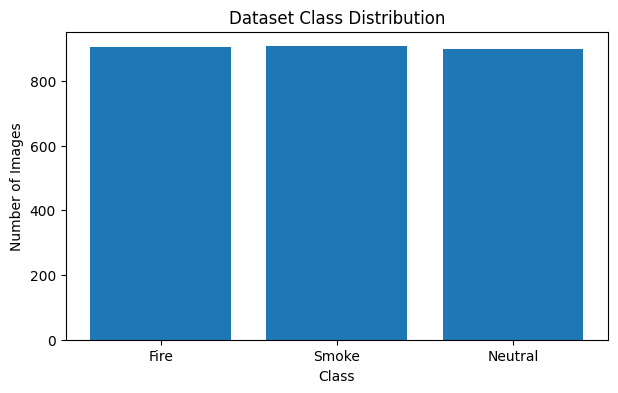

In [10]:
 counts = {
    cls: len(paths)
    for cls, paths in image_paths.items()
}

plt.figure(figsize=(7, 4))
plt.bar(counts.keys(), counts.values())
plt.title("Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

### Observation:
- Based on the observed data for the three class we find that the classes are balanced for Fire, Smoke and Neutral classes
- Fire dataset is 904 images, Smoke is 907 images and Neutral is 900 images in the training dataset

## 02. Display the images

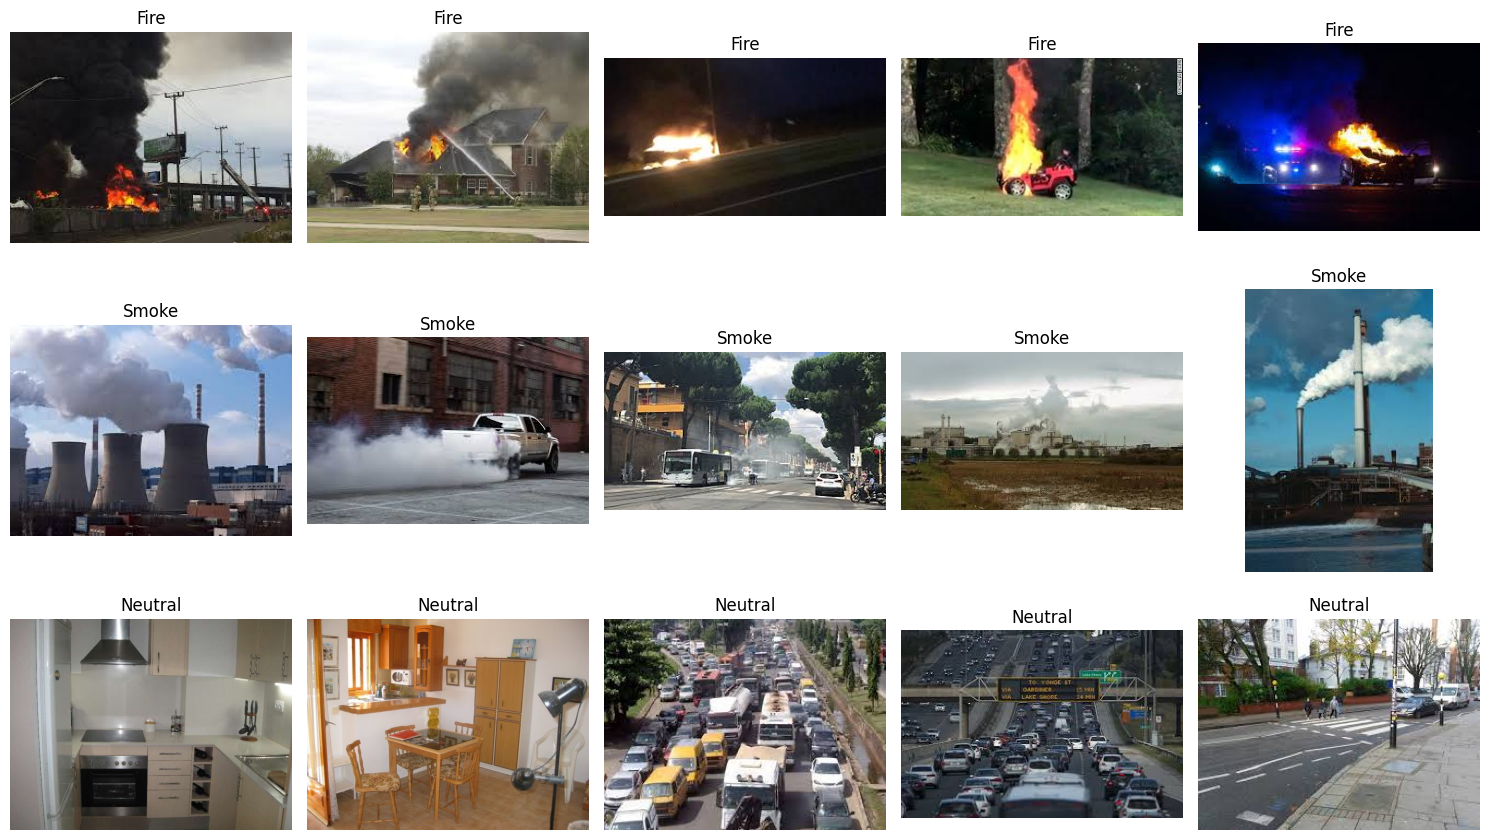

In [11]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for row, cls in enumerate(classes):
    paths = image_paths.get(cls, [])

    for col in range(5):
        ax = axes[row, col]
        ax.axis("off")

        if col >= len(paths):
            continue

        img = cv2.imread(str(paths[col]))

        if img is None:
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        ax.imshow(img)
        ax.set_title(cls)

plt.tight_layout()
plt.show()

### Observation:
- The observed dataset for the fire has both fire and smoke together
- The Smoke datasets are more common in gray/white combination and it is more than common smoke of fire
- The neutral scenarios have organge patterns that might confuse the classifier 

## 03. Inspect Images

In [13]:
records = []
bad_files = []

for cls, paths in image_paths.items():
    for path in paths:
        img = cv2.imread(str(path))

        if img is None:
            bad_files.append(str(path))
            continue

        height, width = img.shape[:2]

        records.append({
            "path": str(path),
            "class": cls,
            "width": width,
            "height": height,
            "aspect_ratio": width / height
        })

df = pd.DataFrame(records)

print(df.groupby("class")[["width", "height"]].describe())
print("Unreadable images:", len(bad_files))

         width                                                              \
         count        mean         std    min    25%    50%    75%     max   
class                                                                        
Fire     904.0  274.752212   30.725097  168.0  259.0  275.0  299.0   429.0   
Neutral  900.0  532.253333  418.034287  176.0  275.0  400.0  640.0  3072.0   
Smoke    907.0  270.390298   34.053033   96.0  259.0  275.0  299.0   427.0   

        height                                                               
         count        mean         std    min     25%    50%    75%     max  
class                                                                        
Fire     904.0  185.107301   25.636323  108.0  168.00  183.0  193.0   300.0  
Neutral  900.0  416.972222  324.276905  145.0  255.75  333.0  500.0  2304.0  
Smoke    907.0  189.084895   27.851832  118.0  168.00  183.0  194.0   307.0  
Unreadable images: 0
